In [1]:
# python pandas

In [5]:
import pandas as pd

In [3]:
import sqlalchemy
import psycopg2

In [2]:
import os
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

username = "postgres"
password = os.getenv("CHINOOK_DB_PASSWORD")
host = "localhost"
port = "5432"
database = "chinook"

if not password:
    raise ValueError("Set CHINOOK_DB_PASSWORD before running the notebook")

db_url = URL.create(
    "postgresql+psycopg2",
    username=username,
    password=password,
    host=host,
    port=int(port),
    database=database
)

engine = create_engine(db_url)


In [3]:
from sqlalchemy import text
with engine.connect() as connection:
    result = connection.execute(
        text("SELECT current_database();")
    )
    
    print(result.fetchone())

('chinook',)


In [6]:
departments = pd.read_csv("data/raw-department.txt", sep="-")

departments

,department_id,department_name
0,1,General
1,2,Sales Support
2,3,IT


In [7]:
budget1 = pd.read_json("data/raw-department-budget.txt", lines=True)

budget1

,sub_dep_id,sub_dep_name,department_id,budget
0,1,managers,1,3000
1,2,managers2,1,1500
2,1,sales support john,2,2000
3,2,sales support joe,2,1000
4,3,sales support johnson,2,2500
5,4,sales support eduards,2,2500


In [8]:
budget2 = pd.read_json("data/raw-department-budget2.txt")

budget2

,sub_dep_id,sub_dep_name,department_id,budget
0,1,IT purchases,3,2000
1,2,IT maintenance,3,1500
2,3,IT other,3,1000


In [9]:
budgets = pd.concat([budget1, budget2], ignore_index=True)

budgets

,sub_dep_id,sub_dep_name,department_id,budget
0,1,managers,1,3000
1,2,managers2,1,1500
2,1,sales support john,2,2000
3,2,sales support joe,2,1000
4,3,sales support johnson,2,2500
5,4,sales support eduards,2,2500
6,1,IT purchases,3,2000
7,2,IT maintenance,3,1500
8,3,IT other,3,1000


In [10]:
department_budget = budgets.merge(departments, how= 'inner', on='department_id')

department_budget

,sub_dep_id,sub_dep_name,department_id,budget,department_name
0,1,managers,1,3000,General
1,2,managers2,1,1500,General
2,1,sales support john,2,2000,Sales Support
3,2,sales support joe,2,1000,Sales Support
4,3,sales support johnson,2,2500,Sales Support
5,4,sales support eduards,2,2500,Sales Support
6,1,IT purchases,3,2000,IT
7,2,IT maintenance,3,1500,IT
8,3,IT other,3,1000,IT


In [11]:
department_budget = department_budget[['department_id', 'department_name', 'budget']]

department_budget

,department_id,department_name,budget
0,1,General,3000
1,1,General,1500
2,2,Sales Support,2000
3,2,Sales Support,1000
4,2,Sales Support,2500
5,2,Sales Support,2500
6,3,IT,2000
7,3,IT,1500
8,3,IT,1000


In [12]:
department_budget = department_budget.groupby(['department_id', 'department_name'])['budget'].sum().reset_index()

department_budget

,department_id,department_name,budget
0,1,General,4500
1,2,Sales Support,8000
2,3,IT,4500


In [13]:
department_budget.to_sql(
    name="department_budget",
    con=engine,
    schema="stg",
    if_exists="replace",
    index=False
)
print("department_budget loaded successfully")

department_budget loaded successfully


In [14]:
# i read the delimiter file and the two JSON files using pandas.
# i combined the two JSON files into one dataframe because they contain two parts of the same table.
# then i joined the department data with the budget data and grouped by department
# to calculate the total budget for each department.
# finally, i loaded the final department_budget table into the stg schema in PostgreSQL.

In [15]:
#API CURRENCIES

In [16]:
dates = pd.read_sql(
    """
    select distinct(invoice.invoicedate)
    from stg.invoice
    order by invoice.invoicedate
    """,
    con=engine)

dates

,invoicedate
0,2018-01-01
1,2018-01-02
2,2018-01-03
3,2018-01-04
4,2018-01-05
...,...
1587,2022-12-18
1588,2022-12-19
1589,2022-12-20
1590,2022-12-21


In [17]:
dates.info()

<class 'pandas.DataFrame'>
RangeIndex: 1592 entries, 0 to 1591
Data columns (total 1 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   invoicedate  1592 non-null   datetime64[us]
dtypes: datetime64[us](1)
memory usage: 12.6 KB


In [18]:
start_date = dates['invoicedate'].min().date()
end_date = dates['invoicedate'].max().date()

In [19]:
import requests
from io import StringIO

url = f"https://api.frankfurter.dev/v2/rates.csv?from={start_date}&to={end_date}&base=USD&quotes=ILS"

response = requests.get(
    url,
    headers={"User-Agent": "Mozilla/5.0"})

response.raise_for_status()

rates = pd.read_csv(
    StringIO(response.text),
    parse_dates=["date"])

In [20]:
rates

,date,base,quote,rate
0,2018-01-01,USD,ILS,3.4708
1,2018-01-02,USD,ILS,3.4616
2,2018-01-03,USD,ILS,3.4601
3,2018-01-04,USD,ILS,3.4503
4,2018-01-05,USD,ILS,3.4429
...,...,...,...,...
1812,2022-12-18,USD,ILS,3.4509
1813,2022-12-19,USD,ILS,3.4515
1814,2022-12-20,USD,ILS,3.4616
1815,2022-12-21,USD,ILS,3.4734


In [21]:
rates = rates.rename(columns={'date': 'invoicedate'})

rates

,invoicedate,base,quote,rate
0,2018-01-01,USD,ILS,3.4708
1,2018-01-02,USD,ILS,3.4616
2,2018-01-03,USD,ILS,3.4601
3,2018-01-04,USD,ILS,3.4503
4,2018-01-05,USD,ILS,3.4429
...,...,...,...,...
1812,2022-12-18,USD,ILS,3.4509
1813,2022-12-19,USD,ILS,3.4515
1814,2022-12-20,USD,ILS,3.4616
1815,2022-12-21,USD,ILS,3.4734


In [22]:
currency = dates.merge(rates, how='left', on='invoicedate')

currency

,invoicedate,base,quote,rate
0,2018-01-01,USD,ILS,3.4708
1,2018-01-02,USD,ILS,3.4616
2,2018-01-03,USD,ILS,3.4601
3,2018-01-04,USD,ILS,3.4503
4,2018-01-05,USD,ILS,3.4429
...,...,...,...,...
1587,2022-12-18,USD,ILS,3.4509
1588,2022-12-19,USD,ILS,3.4515
1589,2022-12-20,USD,ILS,3.4616
1590,2022-12-21,USD,ILS,3.4734


In [23]:
currency.isnull().sum()

invoicedate    0
base           0
quote          0
rate           0
dtype: int64

In [24]:
currency.to_sql(
    name="currency",
    con=engine,
    schema="stg",
    if_exists="replace",
    index=False
)
print("currency loaded successfully")

currency loaded successfully


In [25]:
# the first step was to search through the SQL tables and find the table that contains the dates relevant to the task.
# after that, I read the relevant date column into a Python DataFrame and used an API to get the exchange rates between the US Dollar and the Israeli Shekel.
# then, I merged the tables to create one final table containing the relevant dates, USD as the base currency,
# ILS as the quote currency, and the value of one US Dollar in Israeli Shekels for each date.
# finally, I loaded this table into the "stg" schema under the table name "currency".

In [26]:
# python analysis

In [27]:
import matplotlib.pyplot as plt

In [28]:
# question 1

In [29]:
query = """
select trackid, albumid, artistid,
       artist_name, genreid, genre_name
from dwh.dim_track
"""

dim_track = pd.read_sql(query, engine)

dim_track

,trackid,albumid,artistid,artist_name,genreid,genre_name
0,1,1,1,AC/DC,1,Rock
1,2,2,2,Accept,1,Rock
2,3,3,2,Accept,1,Rock
3,4,3,2,Accept,1,Rock
4,5,3,2,Accept,1,Rock
...,...,...,...,...,...,...
3498,3499,343,226,Eugene Ormandy,24,Classical
3499,3500,344,272,Emerson String Quartet,24,Classical
3500,3501,345,273,"C. Monteverdi, Nigel Rogers - Chiaroscuro; Lon...",24,Classical
3501,3502,346,274,Nash Ensemble,24,Classical


In [30]:
top_artists_albums = (dim_track.groupby(['artistid', 'artist_name'])['albumid'].nunique()
            .reset_index(name='num_of_albums').sort_values('num_of_albums', ascending=False).head(5))

top_artists_albums

,artistid,artist_name,num_of_albums
58,90,Iron Maiden,21
21,22,Led Zeppelin,14
38,58,Deep Purple,11
30,50,Metallica,10
114,150,U2,10


In [31]:
top_artists_tracks = (dim_track.groupby(['artistid', 'artist_name'])['trackid'].count()
            .reset_index(name='num_of_tracks').sort_values('num_of_tracks', ascending=False).head(5))

top_artists_tracks

,artistid,artist_name,num_of_tracks
58,90,Iron Maiden,213
114,150,U2,135
21,22,Led Zeppelin,114
30,50,Metallica,112
113,149,Lost,92


In [32]:
top_genres_tracks = (dim_track.groupby(['genreid', 'genre_name'])['trackid'].count()
            .reset_index(name='num_of_tracks').sort_values('num_of_tracks', ascending=False).head(5))

top_genres_tracks

,genreid,genre_name,num_of_tracks
0,1,Rock,1297
6,7,Latin,579
2,3,Metal,374
3,4,Alternative & Punk,332
1,2,Jazz,130


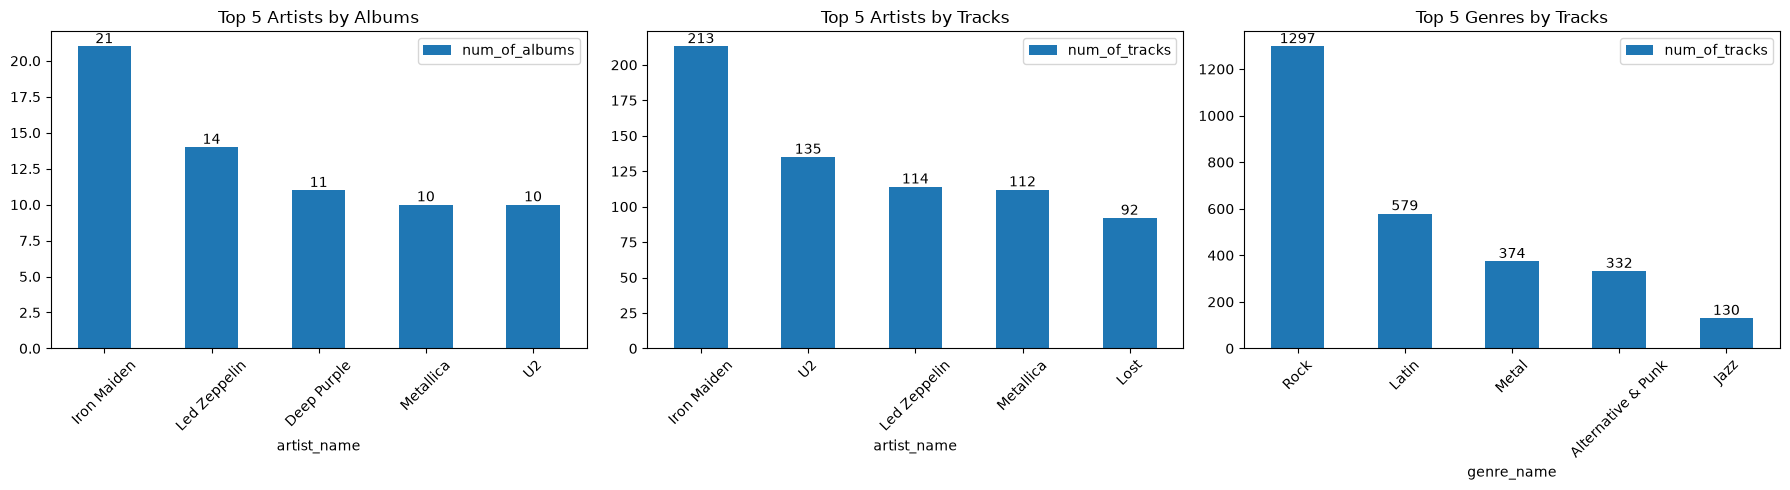

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

top_artists_albums.plot.bar(
    x='artist_name',
    y='num_of_albums',
    ax=axes[0],
    title='Top 5 Artists by Albums',
    rot=45
)

top_artists_tracks.plot.bar(
    x='artist_name',
    y='num_of_tracks',
    ax=axes[1],
    title='Top 5 Artists by Tracks',
    rot=45
)

top_genres_tracks.plot.bar(
    x='genre_name',
    y='num_of_tracks',
    ax=axes[2],
    title='Top 5 Genres by Tracks',
    rot=45
)

axes[0].bar_label(axes[0].containers[0])
axes[1].bar_label(axes[1].containers[0])
axes[2].bar_label(axes[2].containers[0])

plt.tight_layout()
plt.show()

In [94]:
# in this analysis, i found the top 5 artists by number of albums,
# the top 5 artists by number of tracks, and the top 5 genres by number of tracks.
# i used groupby to group the data by artists and genres.
# for albums, i used nunique to count unique albums and avoid counting the same album more than once.
# for tracks, i used count to calculate the total number of tracks.
# then i used sort_values and head(5) to select the top 5 in each category.
# finally, i created one figure with three separate bar charts using subplots.
# this analysis helps us understand which artists and genres have the most content in the database.

In [34]:
# question 2

In [35]:
query = """
select fi.customerid, dc.firstname,
       dc.lastname, fi.invoicedate,
       fi.total as total_usd, cur.rate
from dwh.fact_invoice fi inner join dwh.dim_customer dc
on fi.customerid = dc.customerid inner join dwh.dim_currency cur
on fi.invoicedate = cur.invoicedate
"""

customers_sales = pd.read_sql(query, engine)

customers_sales

,customerid,firstname,lastname,invoicedate,total_usd,rate
0,2,Leonie,Köhler,2018-01-01,1.98,3.4706
1,4,Bjørn,Hansen,2018-01-02,3.96,3.4609
2,8,Daan,Peeters,2018-01-03,5.94,3.4596
3,14,Mark,Philips,2018-01-06,8.91,3.4419
4,37,Fynn,Zimmermann,2018-01-19,0.99,3.4128
...,...,...,...,...,...,...
3806,27,Patrick,Gray,2022-10-13,13.86,3.5708
3807,20,Dan,Miller,2022-11-21,0.99,3.4671
3808,21,Kathy,Chase,2022-12-04,1.98,3.3971
3809,23,John,Gordon,2022-12-04,1.98,3.3971


In [36]:
customers_sales['ils_amount'] = (customers_sales['total_usd'] * customers_sales['rate'])

customers_sales

,customerid,firstname,lastname,invoicedate,total_usd,rate,ils_amount
0,2,Leonie,Köhler,2018-01-01,1.98,3.4706,6.871788
1,4,Bjørn,Hansen,2018-01-02,3.96,3.4609,13.705164
2,8,Daan,Peeters,2018-01-03,5.94,3.4596,20.550024
3,14,Mark,Philips,2018-01-06,8.91,3.4419,30.667329
4,37,Fynn,Zimmermann,2018-01-19,0.99,3.4128,3.378672
...,...,...,...,...,...,...,...
3806,27,Patrick,Gray,2022-10-13,13.86,3.5708,49.491288
3807,20,Dan,Miller,2022-11-21,0.99,3.4671,3.432429
3808,21,Kathy,Chase,2022-12-04,1.98,3.3971,6.726258
3809,23,John,Gordon,2022-12-04,1.98,3.3971,6.726258


In [37]:
customers_sales['full_name'] = (customers_sales['firstname'] + ' ' + customers_sales['lastname'])

customers_sales

,customerid,firstname,lastname,invoicedate,total_usd,rate,ils_amount,full_name
0,2,Leonie,Köhler,2018-01-01,1.98,3.4706,6.871788,Leonie Köhler
1,4,Bjørn,Hansen,2018-01-02,3.96,3.4609,13.705164,Bjørn Hansen
2,8,Daan,Peeters,2018-01-03,5.94,3.4596,20.550024,Daan Peeters
3,14,Mark,Philips,2018-01-06,8.91,3.4419,30.667329,Mark Philips
4,37,Fynn,Zimmermann,2018-01-19,0.99,3.4128,3.378672,Fynn Zimmermann
...,...,...,...,...,...,...,...,...
3806,27,Patrick,Gray,2022-10-13,13.86,3.5708,49.491288,Patrick Gray
3807,20,Dan,Miller,2022-11-21,0.99,3.4671,3.432429,Dan Miller
3808,21,Kathy,Chase,2022-12-04,1.98,3.3971,6.726258,Kathy Chase
3809,23,John,Gordon,2022-12-04,1.98,3.3971,6.726258,John Gordon


In [38]:
top_customers = (customers_sales.groupby(['customerid', 'full_name'])[['total_usd', 'ils_amount']].sum()
            .reset_index().sort_values('total_usd', ascending=False).head(5))

top_customers

,customerid,full_name,total_usd,ils_amount
58,59,Puja Srivastava,71.31,246.201012
131,132,Denise Kelly,65.36,226.877842
178,179,Josephine Gomez,55.44,185.724990
5,6,Helena Holý,49.62,173.321259
25,26,Richard Cunningham,47.62,157.953959


In [39]:
top_customers[['total_usd', 'ils_amount']] = (top_customers[['total_usd', 'ils_amount']].round(2))

top_customers

,customerid,full_name,total_usd,ils_amount
58,59,Puja Srivastava,71.31,246.20
131,132,Denise Kelly,65.36,226.88
178,179,Josephine Gomez,55.44,185.72
5,6,Helena Holý,49.62,173.32
25,26,Richard Cunningham,47.62,157.95


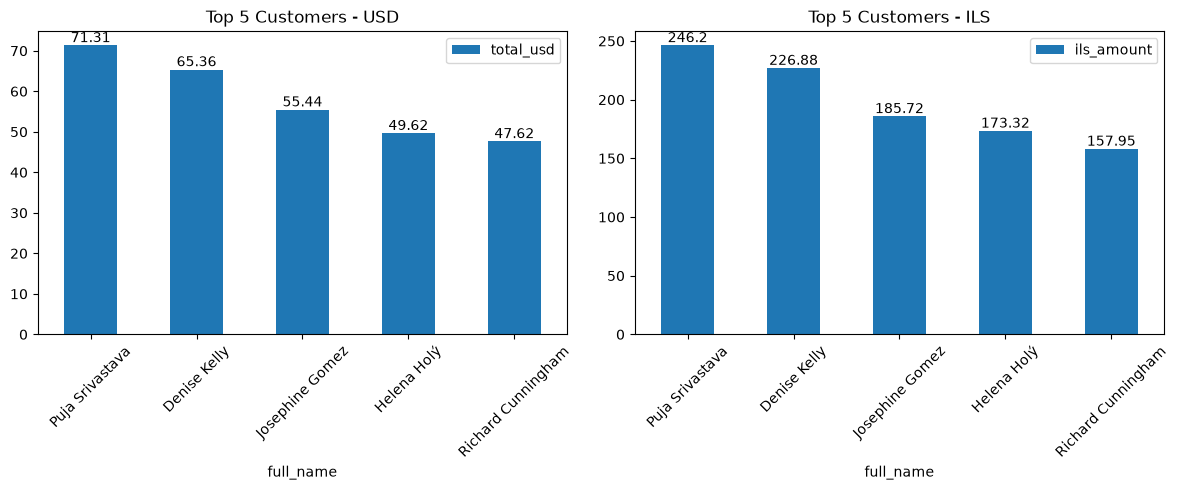

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

top_customers.plot.bar(
    x='full_name',
    y='total_usd',
    ax=axes[0],
    title='Top 5 Customers - USD',
    rot=45
)

top_customers.plot.bar(
    x='full_name',
    y='ils_amount',
    ax=axes[1],
    title='Top 5 Customers - ILS',
    rot=45
)

axes[0].bar_label(axes[0].containers[0])
axes[1].bar_label(axes[1].containers[0])

plt.tight_layout()
plt.show()

In [95]:
# in this analysis, i found the 5 customers who spent the most money.
# first, i retrieved the customer details, invoice amounts, and exchange rates from the database.
# i calculated the amount in ils by multiplying the amount in usd by the exchange rate.
# i also combined the first and last names to create a full name for each customer.
# then i used groupby and sum to calculate the total amount spent by each customer.
# i used sort_values and head(5) to select the 5 customers with the highest spending in usd.
# finally, i used round and created two bar charts to show their spending in usd and ils.
# the analysis helps identify the customers who generate the highest revenue for the company.

In [41]:
# question 3

In [42]:
query = """
select invoicedate, total
from dwh.fact_invoice
"""

monthly_sales = pd.read_sql(query, engine)

monthly_sales

,invoicedate,total
0,2018-01-01,1.98
1,2018-01-02,3.96
2,2018-01-03,5.94
3,2018-01-06,8.91
4,2018-01-19,0.99
...,...,...
3806,2022-10-13,13.86
3807,2022-11-21,0.99
3808,2022-12-04,1.98
3809,2022-12-04,1.98


In [43]:
monthly_sales['invoicedate'].info()

<class 'pandas.Series'>
RangeIndex: 3811 entries, 0 to 3810
Series name: invoicedate
Non-Null Count  Dtype         
--------------  -----         
3811 non-null   datetime64[us]
dtypes: datetime64[us](1)
memory usage: 29.9 KB


In [44]:
monthly_sales['year'] = monthly_sales['invoicedate'].dt.year
monthly_sales['month'] = monthly_sales['invoicedate'].dt.month

monthly_sales

,invoicedate,total,year,month
0,2018-01-01,1.98,2018,1
1,2018-01-02,3.96,2018,1
2,2018-01-03,5.94,2018,1
3,2018-01-06,8.91,2018,1
4,2018-01-19,0.99,2018,1
...,...,...,...,...
3806,2022-10-13,13.86,2022,10
3807,2022-11-21,0.99,2022,11
3808,2022-12-04,1.98,2022,12
3809,2022-12-04,1.98,2022,12


In [45]:
monthly_sales = (monthly_sales.groupby(['year', 'month'])['total'].sum()
            .reset_index(name='total_amount'))

monthly_sales

,year,month,total_amount
0,2018,1,201.01
1,2018,2,237.68
2,2018,3,233.66
3,2018,4,262.45
4,2018,5,227.76
5,2018,6,245.64
6,2018,7,238.66
7,2018,8,209.92
8,2018,9,170.31
9,2018,10,287.17


In [46]:
monthly_sales['year_month'] = (monthly_sales['year'].astype(str) + '-' + monthly_sales['month'].astype(str))

monthly_sales

,year,month,total_amount,year_month
0,2018,1,201.01,2018-1
1,2018,2,237.68,2018-2
2,2018,3,233.66,2018-3
3,2018,4,262.45,2018-4
4,2018,5,227.76,2018-5
5,2018,6,245.64,2018-6
6,2018,7,238.66,2018-7
7,2018,8,209.92,2018-8
8,2018,9,170.31,2018-9
9,2018,10,287.17,2018-10


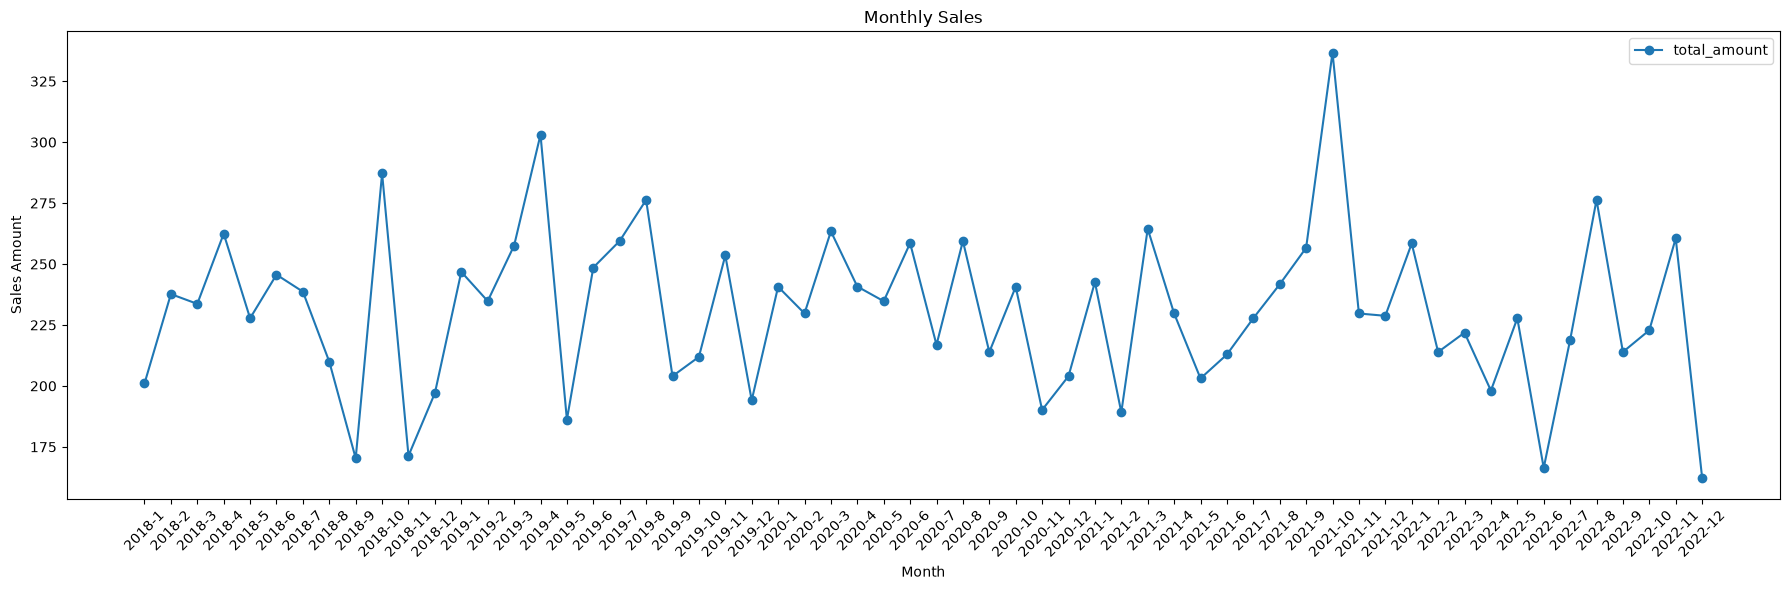

In [47]:
monthly_sales.plot(
    x='year_month',
    y='total_amount',
    kind='line',
    figsize=(18, 6),
    marker='o',
    title='Monthly Sales'
)

plt.xticks(
    range(len(monthly_sales)),
    monthly_sales['year_month'],
    rotation=45
)

plt.xlabel('Month')
plt.ylabel('Sales Amount')
plt.tight_layout()
plt.show()

In [96]:
# in this analysis, i calculated the total sales amount for each month in every year.
# first, i retrieved the invoice dates and sales amounts from the database.
# i checked the date column to make sure it was stored as a datetime type.
# then i used dt.year and dt.month to create separate columns for the year and month.
# i used groupby and sum to calculate the total sales for each month.
# after that, i combined the year and month into one column for the graph.
# finally, i created a line chart to show how monthly sales changed over time.
# this analysis helps identify sales trends and months with higher or lower sales.

In [48]:
# question 4

In [49]:
query = """
select dt.trackid,
       dt.seconds, fil.line_total
from dwh.dim_track dt left join dwh.fact_invoiceline fil
on dt.trackid = fil.trackid
"""

track_sales = pd.read_sql(query, engine)

track_sales

,trackid,seconds,line_total
0,2,342,0.99
1,4,252,0.99
2,6,205,0.99
3,8,210,0.99
4,10,263,0.99
...,...,...,...
13732,3039,226,NaN
13733,3352,327,NaN
13734,3167,2587,NaN
13735,3345,2605,NaN


In [50]:
track_sales['minutes'] = track_sales['seconds'] / 60

track_sales

,trackid,seconds,line_total,minutes
0,2,342,0.99,5.700000
1,4,252,0.99,4.200000
2,6,205,0.99,3.416667
3,8,210,0.99,3.500000
4,10,263,0.99,4.383333
...,...,...,...,...
13732,3039,226,NaN,3.766667
13733,3352,327,NaN,5.450000
13734,3167,2587,NaN,43.116667
13735,3345,2605,NaN,43.416667


In [51]:
track_sales['line_total'] = track_sales['line_total'].fillna(0)

track_sales

,trackid,seconds,line_total,minutes
0,2,342,0.99,5.700000
1,4,252,0.99,4.200000
2,6,205,0.99,3.416667
3,8,210,0.99,3.500000
4,10,263,0.99,4.383333
...,...,...,...,...
13732,3039,226,0.00,3.766667
13733,3352,327,0.00,5.450000
13734,3167,2587,0.00,43.116667
13735,3345,2605,0.00,43.416667


In [52]:
track_sales = (track_sales.groupby(['trackid', 'minutes'])['line_total'].sum()
            .reset_index(name='total_amount'))

track_sales

,trackid,minutes,total_amount
0,1,5.716667,6.93
1,2,5.700000,6.93
2,3,3.833333,2.97
3,4,4.200000,5.94
4,5,6.250000,2.97
...,...,...,...
3498,3499,4.766667,0.99
3499,3500,2.316667,1.98
3500,3501,1.100000,0.00
3501,3502,3.683333,0.00


In [53]:
track_sales['minutes'] = track_sales['minutes'].round(2)
track_sales['total_amount'] = track_sales['total_amount'].round(2)

track_sales

,trackid,minutes,total_amount
0,1,5.72,6.93
1,2,5.70,6.93
2,3,3.83,2.97
3,4,4.20,5.94
4,5,6.25,2.97
...,...,...,...
3498,3499,4.77,0.99
3499,3500,2.32,1.98
3500,3501,1.10,0.00
3501,3502,3.68,0.00


In [54]:
correlation = track_sales['minutes'].corr(track_sales['total_amount'])

correlation

np.float64(0.14584529979561092)

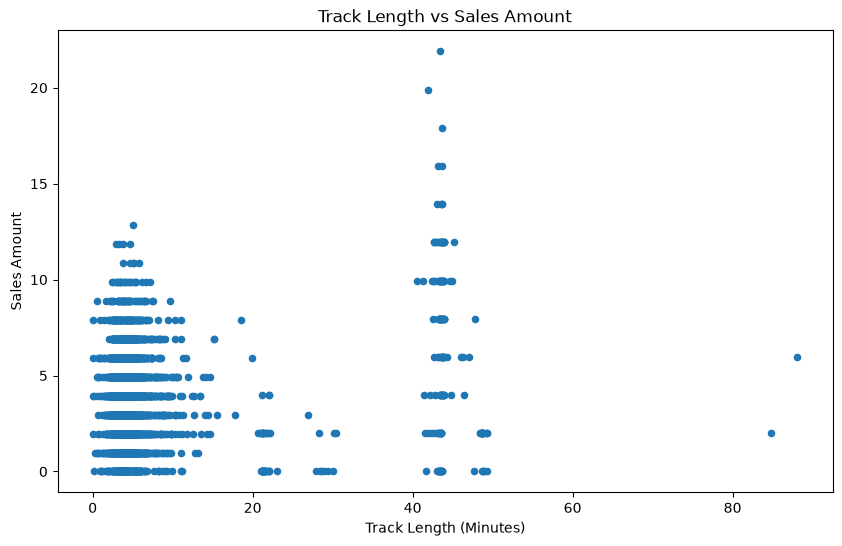

In [55]:
track_sales.plot.scatter(
    x='minutes',
    y='total_amount',
    figsize=(10, 6),
    title='Track Length vs Sales Amount'
)

plt.xlabel('Track Length (Minutes)')
plt.ylabel('Sales Amount')
plt.show()

In [56]:
# the correlation between track length and sales amount is approximately 0.14, which means the relationship is very weak.
# we can see that shorter tracks, between 0 and 20 minutes, have a wide range of sales amounts, from no sales at all to almost 15.
# then there is a jump to longer tracks, above 40 minutes. these tracks also show a wide range of sales, from no sales to more than 20.
# in addition, there are two unusual tracks with a length of more than 80 minutes, and both of them were sold.
# because there is no clear and consistent increase or decrease in sales as track length increases, the correlation is very weak.

In [57]:
# question 5

In [58]:
query = """
select fi.customerid, fil.trackid,
       dt.track_name, dt.genreid, dt.genre_name
from dwh.fact_invoice fi inner join dwh.fact_invoiceline fil
on fi.invoiceid = fil.invoiceid inner join dwh.dim_track dt
on fil.trackid = dt.trackid
"""

sales_data = pd.read_sql(query, engine)

sales_data

,customerid,trackid,track_name,genreid,genre_name
0,2,2,Balls to the Wall,1,Rock
1,2,4,Restless and Wild,1,Rock
2,4,6,Put The Finger On You,1,Rock
3,4,8,Inject The Venom,1,Rock
4,4,10,Evil Walks,1,Rock
...,...,...,...,...,...
13458,73,2568,Black Light Syndrome,1,Rock
13459,73,1048,It Was A Very Good Year,12,Easy Listening
13460,73,663,Chão de Giz (Elba Ramalho),7,Latin
13461,73,2523,Morning Dance,2,Jazz


In [59]:
customer_genres = (sales_data.groupby(['customerid', 'genreid', 'genre_name'])['trackid'].count()
            .reset_index(name='num_of_tracks').sort_values(['customerid', 'num_of_tracks'], ascending=[True, False]))

customer_genres

,customerid,genreid,genre_name,num_of_tracks
0,1,1,Rock,14
2,1,7,Latin,11
3,1,8,Reggae,3
1,1,3,Metal,2
4,1,9,Pop,2
...,...,...,...,...
4316,654,7,Latin,1
4317,655,2,Jazz,1
4318,655,4,Alternative & Punk,1
4319,656,1,Rock,1


In [60]:
top_genres = (customer_genres.sort_values(['customerid', 'num_of_tracks'],ascending=[True, False]).groupby('customerid').head(2))

top_genres

,customerid,genreid,genre_name,num_of_tracks
0,1,1,Rock,14
2,1,7,Latin,11
8,2,1,Rock,17
11,2,6,Blues,9
17,3,3,Metal,10
...,...,...,...,...
4316,654,7,Latin,1
4317,655,2,Jazz,1
4318,655,4,Alternative & Punk,1
4319,656,1,Rock,1


In [61]:
track_popularity = (sales_data.groupby(['trackid', 'track_name', 'genreid', 'genre_name'])['customerid'].count()
            .reset_index(name='num_of_sales').sort_values('num_of_sales', ascending=False))

track_popularity

,trackid,track_name,genreid,genre_name,num_of_sales
894,898,Bell Bottom Blues,6,Blues,13
633,635,Lemon Drop,2,Jazz,12
1219,1226,Can I Play With Madness,3,Metal,12
472,473,When I Come Around,4,Alternative & Punk,12
2648,2672,Paint It Black,1,Rock,12
...,...,...,...,...,...
3217,3484,Adios nonino,24,Classical,1
3218,3485,Symphony No. 3 Op. 36 for Orchestra and Sopran...,24,Classical,1
3219,3486,"Act IV, Symphony",24,Classical,1
3189,3441,Two Fanfares for Orchestra: II. Short Ride in ...,24,Classical,1


In [62]:
recommendations = top_genres.merge(track_popularity, on=['genreid', 'genre_name'])

recommendations

,customerid,genreid,genre_name,num_of_tracks,trackid,track_name,num_of_sales
0,1,1,Rock,14,2672,Paint It Black,12
1,1,1,Rock,14,1401,Judgement Of Heaven,11
2,1,1,Rock,14,2153,Elderly Woman Behind The Counter In A Small Town,11
3,1,1,Rock,14,2968,City Of Blinding Lights,11
4,1,1,Rock,14,1799,Shakes and Ladders,10
...,...,...,...,...,...,...,...
1054860,657,7,Latin,1,3160,Sapopemba e Maxambomba,1
1054861,657,7,Latin,1,3163,Samba pras moças,1
1054862,657,7,Latin,1,3164,Verdade,1
1054863,657,7,Latin,1,3356,Muita Bobeira,1


In [63]:
bought_tracks = (sales_data[['customerid', 'trackid']].drop_duplicates())

bought_tracks

,customerid,trackid
0,2,2
1,2,4
2,4,6
3,4,8
4,4,10
...,...,...
13458,73,2568
13459,73,1048
13460,73,663
13461,73,2523


In [64]:
recommendations = recommendations.merge(bought_tracks, on=['customerid', 'trackid'], how='left', indicator=True)

recommendations

,customerid,genreid,genre_name,num_of_tracks,trackid,track_name,num_of_sales,_merge
0,1,1,Rock,14,2672,Paint It Black,12,left_only
1,1,1,Rock,14,1401,Judgement Of Heaven,11,left_only
2,1,1,Rock,14,2153,Elderly Woman Behind The Counter In A Small Town,11,left_only
3,1,1,Rock,14,2968,City Of Blinding Lights,11,left_only
4,1,1,Rock,14,1799,Shakes and Ladders,10,left_only
...,...,...,...,...,...,...,...,...
1054860,657,7,Latin,1,3160,Sapopemba e Maxambomba,1,left_only
1054861,657,7,Latin,1,3163,Samba pras moças,1,left_only
1054862,657,7,Latin,1,3164,Verdade,1,left_only
1054863,657,7,Latin,1,3356,Muita Bobeira,1,left_only


In [65]:
recommendations['_merge'].value_counts()

_merge
left_only     1046686
both             8179
right_only          0
Name: count, dtype: int64

In [66]:
recommendations = recommendations[recommendations['_merge'] == 'left_only'].drop(columns='_merge')

recommendations

,customerid,genreid,genre_name,num_of_tracks,trackid,track_name,num_of_sales
0,1,1,Rock,14,2672,Paint It Black,12
1,1,1,Rock,14,1401,Judgement Of Heaven,11
2,1,1,Rock,14,2153,Elderly Woman Behind The Counter In A Small Town,11
3,1,1,Rock,14,2968,City Of Blinding Lights,11
4,1,1,Rock,14,1799,Shakes and Ladders,10
...,...,...,...,...,...,...,...
1054860,657,7,Latin,1,3160,Sapopemba e Maxambomba,1
1054861,657,7,Latin,1,3163,Samba pras moças,1
1054862,657,7,Latin,1,3164,Verdade,1
1054863,657,7,Latin,1,3356,Muita Bobeira,1


In [67]:
recommendations = recommendations.sort_values(['customerid', 'genreid', 'num_of_sales'],ascending=[True, True, False])

recommendations

,customerid,genreid,genre_name,num_of_tracks,trackid,track_name,num_of_sales
0,1,1,Rock,14,2672,Paint It Black,12
1,1,1,Rock,14,1401,Judgement Of Heaven,11
2,1,1,Rock,14,2153,Elderly Woman Behind The Counter In A Small Town,11
3,1,1,Rock,14,2968,City Of Blinding Lights,11
4,1,1,Rock,14,1799,Shakes and Ladders,10
...,...,...,...,...,...,...,...
1054860,657,7,Latin,1,3160,Sapopemba e Maxambomba,1
1054861,657,7,Latin,1,3163,Samba pras moças,1
1054862,657,7,Latin,1,3164,Verdade,1
1054863,657,7,Latin,1,3356,Muita Bobeira,1


In [68]:
recommendations = (recommendations.groupby(['customerid', 'genreid']).head(3))

recommendations

,customerid,genreid,genre_name,num_of_tracks,trackid,track_name,num_of_sales
0,1,1,Rock,14,2672,Paint It Black,12
1,1,1,Rock,14,1401,Judgement Of Heaven,11
2,1,1,Rock,14,2153,Elderly Woman Behind The Counter In A Small Town,11
1233,1,7,Latin,11,380,Samba da Bençaco,11
1234,1,7,Latin,11,1523,My Brother,10
...,...,...,...,...,...,...,...
1053079,656,1,Rock,1,1401,Judgement Of Heaven,11
1053080,656,1,Rock,1,2153,Elderly Woman Behind The Counter In A Small Town,11
1054311,657,7,Latin,1,380,Samba da Bençaco,11
1054312,657,7,Latin,1,1523,My Brother,10


In [69]:
# check for a specific customer

In [70]:
recommendations[recommendations['customerid'] == 444]

,customerid,genreid,genre_name,num_of_tracks,trackid,track_name,num_of_sales
725705,444,1,Rock,5,2672,Paint It Black,12
725706,444,1,Rock,5,1401,Judgement Of Heaven,11
725707,444,1,Rock,5,2153,Elderly Woman Behind The Counter In A Small Town,11
726938,444,7,Latin,3,380,Samba da Bençaco,11
726939,444,7,Latin,3,1523,My Brother,10
726940,444,7,Latin,3,241,Geni E O Zepelim,10


In [71]:
# this recommendation system uses each customer's purchase history to identify their preferred genres.
# first, i count how many tracks each customer purchased from every genre and select up to the top 2 genres for each customer.
# then, i calculate track popularity based on the number of times each track was purchased.
# the preferred genres are combined with the popularity data to create possible recommendations for each customer.
# i also create a list of tracks that each customer already purchased and remove them from the recommendation list.
# after that, the remaining tracks are sorted by popularity, and the top 3 tracks from each preferred genre are selected.
# in most cases, this creates 6 recommendations for each customer: 3 tracks from each of the top 2 preferred genres.
# if a customer has purchase history in only one genre, only 3 recommendations are returned,
# because there is not enough information to identify a second preferred genre without making an assumption.

In [72]:
# additional python analysis

In [73]:
# this analysis checks if genre track sales in january and february can be used as an early indicator for the rest of the year.
# the goal is to analyze the 10 countries with the highest number of orders in a selected year.
# for each country, i compare the top 3 genres in january and february with the top 3 genres from march to december.
# this can help the company understand if early genre trends remain stable during the rest of the year
# and support decisions such as marketing, promotions, and catalog planning.

In [74]:
query = """
select fi.invoiceid, fi.invoicedate, fi.billingcountry,
       dt.genreid, dt.genre_name, fil.trackid, fil.line_total
from dwh.fact_invoice fi inner join dwh.fact_invoiceline fil
on fi.invoiceid = fil.invoiceid inner join dwh.dim_track dt
on fil.trackid = dt.trackid
"""

trend_data = pd.read_sql(query, engine)

trend_data

,invoiceid,invoicedate,billingcountry,genreid,genre_name,trackid,line_total
0,1,2018-01-01,Germany,1,Rock,2,0.99
1,1,2018-01-01,Germany,1,Rock,4,0.99
2,2,2018-01-02,Norway,1,Rock,6,0.99
3,2,2018-01-02,Norway,1,Rock,8,0.99
4,2,2018-01-02,Norway,1,Rock,10,0.99
...,...,...,...,...,...,...,...
13458,3811,2022-03-23,India,1,Rock,2568,0.99
13459,3811,2022-03-23,India,12,Easy Listening,1048,0.99
13460,3811,2022-03-23,India,7,Latin,663,0.99
13461,3811,2022-03-23,India,2,Jazz,2523,0.99


In [75]:
trend_data['invoicedate'].info()

<class 'pandas.Series'>
RangeIndex: 13463 entries, 0 to 13462
Series name: invoicedate
Non-Null Count  Dtype         
--------------  -----         
13463 non-null  datetime64[us]
dtypes: datetime64[us](1)
memory usage: 105.3 KB


In [76]:
year_data = trend_data[trend_data['invoicedate'].dt.year == 2021]

year_data

,invoiceid,invoicedate,billingcountry,genreid,genre_name,trackid,line_total
1351,250,2021-01-01,Australia,3,Metal,1213,0.99
1352,250,2021-01-01,Australia,3,Metal,1222,0.99
1353,250,2021-01-01,Australia,3,Metal,1231,0.99
1354,250,2021-01-01,Australia,1,Rock,1240,0.99
1355,250,2021-01-01,Australia,13,Heavy Metal,1249,0.99
...,...,...,...,...,...,...,...
13450,3808,2021-03-12,India,7,Latin,1118,0.99
13451,3808,2021-03-12,India,1,Rock,1027,0.99
13452,3808,2021-03-12,India,1,Rock,1322,0.99
13456,3810,2021-12-14,United States,3,Metal,1837,0.99


In [77]:
top_countries = (year_data.groupby('billingcountry')['invoiceid'].nunique()
            .reset_index(name='num_of_orders').sort_values('num_of_orders', ascending=False).head(10))

top_countries

,billingcountry,num_of_orders
92,United States,77
39,India,75
19,China,68
12,Brazil,47
72,Russian Federation,37
45,Japan,35
53,Mexico,25
17,Canada,19
75,South Africa,19
66,Philippines,19


In [78]:
top_10_countries = top_countries['billingcountry']

top_10_countries

92         United States
39                 India
19                 China
12                Brazil
72    Russian Federation
45                 Japan
53                Mexico
17                Canada
75          South Africa
66           Philippines
Name: billingcountry, dtype: str

In [79]:
top_countries_data = year_data[year_data['billingcountry'].isin(top_10_countries)]

top_countries_data

,invoiceid,invoicedate,billingcountry,genreid,genre_name,trackid,line_total
1365,251,2021-01-09,Brazil,3,Metal,1344,0.99
1366,252,2021-01-22,Brazil,3,Metal,1345,0.99
1367,252,2021-01-22,Brazil,3,Metal,1346,0.99
1368,253,2021-01-22,Brazil,3,Metal,1348,0.99
1369,253,2021-01-22,Brazil,3,Metal,1350,0.99
...,...,...,...,...,...,...,...
13450,3808,2021-03-12,India,7,Latin,1118,0.99
13451,3808,2021-03-12,India,1,Rock,1027,0.99
13452,3808,2021-03-12,India,1,Rock,1322,0.99
13456,3810,2021-12-14,United States,3,Metal,1837,0.99


In [80]:
jan_feb_data = top_countries_data[top_countries_data['invoicedate'].dt.month.isin([1, 2])]

jan_feb_data

,invoiceid,invoicedate,billingcountry,genreid,genre_name,trackid,line_total
1365,251,2021-01-09,Brazil,3,Metal,1344,0.99
1366,252,2021-01-22,Brazil,3,Metal,1345,0.99
1367,252,2021-01-22,Brazil,3,Metal,1346,0.99
1368,253,2021-01-22,Brazil,3,Metal,1348,0.99
1369,253,2021-01-22,Brazil,3,Metal,1350,0.99
...,...,...,...,...,...,...,...
13027,3678,2021-02-03,South Africa,7,Latin,1767,0.99
13028,3678,2021-02-03,South Africa,1,Rock,423,0.99
13029,3678,2021-02-03,South Africa,10,Soundtrack,1073,0.99
13205,3731,2021-02-11,South Africa,3,Metal,1883,0.99


In [81]:
jan_feb_genres = (jan_feb_data.groupby(['billingcountry', 'genre_name'])['trackid'].count()
            .reset_index(name='jan_feb_tracks'))

jan_feb_genres

,billingcountry,genre_name,jan_feb_tracks
0,Brazil,Alternative & Punk,3
1,Brazil,Jazz,2
2,Brazil,Latin,2
3,Brazil,Metal,8
4,Brazil,Rock,4
...,...,...,...
65,United States,Metal,6
66,United States,R&B/Soul,4
67,United States,Rock,13
68,United States,Soundtrack,2


In [82]:
jan_feb_genres = jan_feb_genres.sort_values(['billingcountry', 'jan_feb_tracks'],ascending=[True, False])

jan_feb_genres

,billingcountry,genre_name,jan_feb_tracks
3,Brazil,Metal,8
4,Brazil,Rock,4
0,Brazil,Alternative & Punk,3
1,Brazil,Jazz,2
2,Brazil,Latin,2
...,...,...,...
62,United States,Alternative & Punk,3
64,United States,Latin,2
68,United States,Soundtrack,2
63,United States,Jazz,1


In [83]:
jan_feb_top3 = (jan_feb_genres.groupby('billingcountry').head(3))

jan_feb_top3

,billingcountry,genre_name,jan_feb_tracks
3,Brazil,Metal,8
4,Brazil,Rock,4
0,Brazil,Alternative & Punk,3
9,Canada,Metal,4
8,Canada,Latin,2
10,Canada,R&B/Soul,1
21,China,Rock,24
11,China,Alternative & Punk,9
17,China,Latin,8
28,India,Rock,10


In [84]:
mar_dec_data = top_countries_data[top_countries_data['invoicedate'].dt.month >= 3]

mar_dec_data

,invoiceid,invoicedate,billingcountry,genreid,genre_name,trackid,line_total
1427,264,2021-03-03,Brazil,7,Latin,1677,0.99
1428,264,2021-03-03,Brazil,7,Latin,1686,0.99
1429,264,2021-03-03,Brazil,7,Latin,1695,0.99
1430,264,2021-03-03,Brazil,1,Rock,1704,0.99
1431,264,2021-03-03,Brazil,1,Rock,1713,0.99
...,...,...,...,...,...,...,...
13450,3808,2021-03-12,India,7,Latin,1118,0.99
13451,3808,2021-03-12,India,1,Rock,1027,0.99
13452,3808,2021-03-12,India,1,Rock,1322,0.99
13456,3810,2021-12-14,United States,3,Metal,1837,0.99


In [85]:
mar_dec_genres = (mar_dec_data.groupby(['billingcountry', 'genre_name'])['trackid'].count()
            .reset_index(name='mar_dec_tracks'))

mar_dec_genres

,billingcountry,genre_name,mar_dec_tracks
0,Brazil,Alternative & Punk,8
1,Brazil,Blues,1
2,Brazil,Classical,6
3,Brazil,Easy Listening,1
4,Brazil,Electronica/Dance,1
...,...,...,...
141,United States,Sci Fi & Fantasy,6
142,United States,Science Fiction,1
143,United States,Soundtrack,5
144,United States,TV Shows,9


In [86]:
mar_dec_genres = mar_dec_genres.sort_values(['billingcountry', 'mar_dec_tracks'], ascending=[True, False])

mar_dec_genres

,billingcountry,genre_name,mar_dec_tracks
12,Brazil,Rock,55
7,Brazil,Latin,45
8,Brazil,Metal,12
0,Brazil,Alternative & Punk,8
2,Brazil,Classical,6
...,...,...,...
145,United States,World,2
131,United States,Easy Listening,1
132,United States,Hip Hop/Rap,1
136,United States,Pop,1


In [87]:
mar_dec_top3 = (mar_dec_genres.groupby('billingcountry').head(3))

mar_dec_top3

,billingcountry,genre_name,mar_dec_tracks
12,Brazil,Rock,55
7,Brazil,Latin,45
8,Brazil,Metal,12
25,Canada,Rock,21
21,Canada,Latin,14
22,Canada,Metal,8
38,China,Rock,68
33,China,Latin,29
27,China,Alternative & Punk,22
60,India,Rock,78


In [88]:
comparison = jan_feb_top3.merge(mar_dec_top3,on=['billingcountry', 'genre_name'],how='left')

comparison

,billingcountry,genre_name,jan_feb_tracks,mar_dec_tracks
0,Brazil,Metal,8,12.0
1,Brazil,Rock,4,55.0
2,Brazil,Alternative & Punk,3,NaN
3,Canada,Metal,4,8.0
4,Canada,Latin,2,14.0
5,Canada,R&B/Soul,1,NaN
6,China,Rock,24,68.0
7,China,Alternative & Punk,9,22.0
8,China,Latin,8,29.0
9,India,Rock,10,78.0


In [89]:
comparison['stayed_top3'] = comparison['mar_dec_tracks'].notna()

comparison

,billingcountry,genre_name,jan_feb_tracks,mar_dec_tracks,stayed_top3
0,Brazil,Metal,8,12.0,True
1,Brazil,Rock,4,55.0,True
2,Brazil,Alternative & Punk,3,NaN,False
3,Canada,Metal,4,8.0,True
4,Canada,Latin,2,14.0,True
5,Canada,R&B/Soul,1,NaN,False
6,China,Rock,24,68.0,True
7,China,Alternative & Punk,9,22.0,True
8,China,Latin,8,29.0,True
9,India,Rock,10,78.0,True


In [90]:
top3_retention = comparison['stayed_top3'].mean() * 100

top3_retention

np.float64(80.0)

In [91]:
country_retention = (comparison.groupby('billingcountry')['stayed_top3'].mean().mul(100).round(2)
    .reset_index(name='retention_rate'))

country_retention

,billingcountry,retention_rate
0,Brazil,66.67
1,Canada,66.67
2,China,100.00
3,India,66.67
4,Japan,66.67
5,Mexico,100.00
6,Philippines,100.00
7,Russian Federation,100.00
8,South Africa,66.67
9,United States,66.67


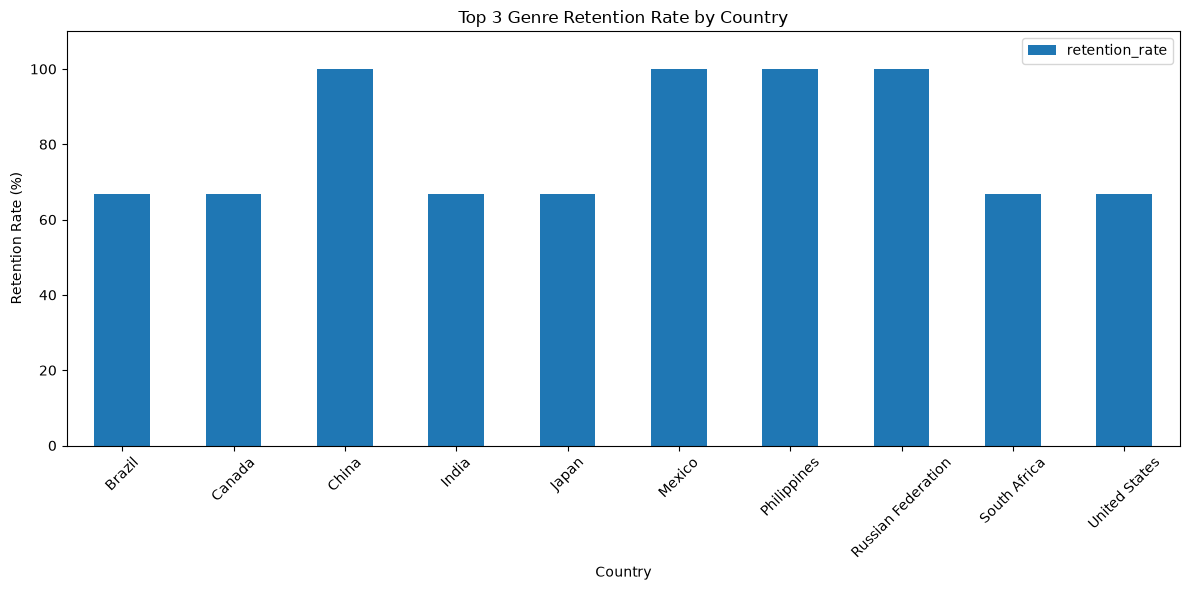

In [92]:
country_retention.plot.bar(
    x='billingcountry',
    y='retention_rate',
    figsize=(12, 6),
    title='Top 3 Genre Retention Rate by Country')

plt.xlabel('Country')
plt.ylabel('Retention Rate (%)')
plt.xticks(rotation=45)
plt.ylim(0, 110)
plt.tight_layout()
plt.show()

In [93]:
# the analysis shows that genre preferences were relatively stable during the year.
# overall, 80% of the genres that were in the top 3 in january and february also remained in the top 3 from march to december.
# in some countries, the retention rate was 100%, while in others it was 66.67%.
# this suggests that early genre trends can be useful as an indicator for the rest of the year,
# but they should not be treated as a perfect prediction.